# Unemployment Analysis with Python
**CodeAlpha Data Science Internship — Task 2**

- **Student:** Nour Ali Mohamed
- **Student ID:** CA/DF1/414910
- **Internship domain:** Data Science

## 1. Project Introduction

This project explores unemployment indicators in India and investigates how the unemployment rate changed during the COVID-19 period. It uses two supplied CSV datasets with monthly observations.

### Objectives
- Clean and validate the supplied datasets.
- Explore unemployment, employment, and labour-force participation indicators.
- Compare patterns across states, rural/urban areas, and broad regions.
- Examine changes around the COVID-19 period beginning in March 2020.
- Identify observable patterns and communicate evidence-based insights.

### Important interpretation note
These datasets are observational and cover a limited period around 2019–2020. A change during the COVID-19 period is an association in the data, not proof that COVID-19 alone caused the change. The available time span is also too short to establish reliable recurring annual seasonality.

## 2. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 3. Load the Datasets

The two original CSV files are kept in the `dataset` folder. The first dataset contains state-level observations split by rural and urban areas. The second contains monthly state-level observations with broad regional labels and coordinates.

In [2]:
DATASET_DIR = Path("dataset")
DATASET_ONE = DATASET_DIR / "Unemployment in India.csv"
DATASET_TWO = DATASET_DIR / "Unemployment_Rate_upto_11_2020.csv"

for dataset_path in (DATASET_ONE, DATASET_TWO):
    if not dataset_path.is_file():
        raise FileNotFoundError(
            f"Could not find {dataset_path.resolve()}. "
            "Keep both supplied CSV files inside the project's dataset folder."
        )

unemployment_area_raw = pd.read_csv(DATASET_ONE)
unemployment_region_raw = pd.read_csv(DATASET_TWO)

print("Dataset 1 — state and area observations")
print("Shape:", unemployment_area_raw.shape)
display(unemployment_area_raw.head())
print("\nDataset 2 — regional observations")
print("Shape:", unemployment_region_raw.shape)
display(unemployment_region_raw.head())

Dataset 1 — state and area observations
Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,"11,999,139.00",43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,"11,755,881.00",42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,"12,086,707.00",43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,"12,285,693.00",43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,"12,256,762.00",44.68,Rural



Dataset 2 — regional observations
Shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.91,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.91,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.91,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.91,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.91,79.74


## 4. Initial Data Inspection

In [3]:
def inspect_dataset(dataframe, dataset_name):
    print(f"--- {dataset_name} ---")
    print("Dimensions:", dataframe.shape)
    print("\nColumns and data types:")
    display(dataframe.dtypes.rename("data_type").to_frame())
    print("\nMissing values:")
    display(dataframe.isna().sum().rename("missing_values").to_frame())
    print("\nExact duplicate rows:", int(dataframe.duplicated().sum()))
    print("\nDescriptive statistics:")
    display(dataframe.describe(include="all").T)

inspect_dataset(unemployment_area_raw, "Unemployment in India")
inspect_dataset(unemployment_region_raw, "Unemployment Rate up to November 2020")

--- Unemployment in India ---
Dimensions: (768, 7)

Columns and data types:


,data_type
Region,object
Date,object
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object



Missing values:


,missing_values
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28



Exact duplicate rows: 27

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,14,31-10-2019,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,740,2,Monthly,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.00,NaN,NaN,NaN,11.79,10.72,0.00,4.66,8.35,15.89,76.74
Estimated Employed,740.00,NaN,NaN,NaN,"7,204,460.03","8,087,988.43","49,420.00","1,190,404.50","4,744,178.50","11,275,489.50","45,777,509.00"
Estimated Labour Participation Rate (%),740.00,NaN,NaN,NaN,42.63,8.11,13.33,38.06,41.16,45.51,72.57
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (2 outputs left out)


Missing values:


,missing_values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0



Exact duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,267,27,Andhra Pradesh,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,267,10,31-05-2020,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,267,1,M,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),267.00,NaN,NaN,NaN,12.24,10.80,0.50,4.84,9.65,16.75,75.85
Estimated Employed,267.00,NaN,NaN,NaN,"13,962,105.72","13,366,318.36","117,542.00","2,838,930.50","9,732,417.00","21,878,686.00","59,433,759.00"
Estimated Labour Participation Rate (%),267.00,NaN,NaN,NaN,41.68,7.85,16.77,37.27,40.39,44.05,69.69
Region.1,267,5,North,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitude,267.00,NaN,NaN,NaN,22.83,6.27,10.85,18.11,23.61,27.28,33.78
latitude,267.00,NaN,NaN,NaN,80.53,5.83,71.19,76.09,79.02,85.28,92.94


## 5. Data Cleaning and Preparation

Cleaning decisions are based on the actual files:
- Remove leading/trailing whitespace from column names and text values.
- Remove fully empty rows from the first dataset.
- Remove exact duplicate records from the first dataset.
- Convert date fields to pandas datetime using day-first parsing.
- Convert measurement columns to numeric values.
- Keep the original state, area, and regional categories.
- Retain the geographic coordinates in the second dataset for possible mapping or later analysis; they are not required for the time-series charts.

The first file has 28 fully empty rows and 27 exact duplicate rows. After removing those records, it contains 740 complete observations. The second file contains 267 complete observations with no exact duplicate rows.

In [4]:
def clean_unemployment_data(dataframe):
    cleaned = dataframe.copy()
    cleaned.columns = cleaned.columns.str.strip()

    for column in cleaned.select_dtypes(include="object").columns:
        cleaned[column] = cleaned[column].astype("string").str.strip()

    cleaned = cleaned.dropna(how="all").drop_duplicates().copy()

    if "Date" in cleaned.columns:
        cleaned["Date"] = pd.to_datetime(
            cleaned["Date"], format="%d-%m-%Y", errors="coerce"
        )

    numeric_columns = [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)",
        "longitude",
        "latitude",
    ]
    for column in numeric_columns:
        if column in cleaned.columns:
            cleaned[column] = pd.to_numeric(cleaned[column], errors="coerce")

    return cleaned.reset_index(drop=True)

unemployment_area = clean_unemployment_data(unemployment_area_raw)
unemployment_region = clean_unemployment_data(unemployment_region_raw)

print("Cleaned dataset 1:", unemployment_area.shape)
print("Cleaned dataset 2:", unemployment_region.shape)
print("\nRemaining missing values — dataset 1:")
display(unemployment_area.isna().sum().to_frame("missing_values"))
print("\nRemaining missing values — dataset 2:")
display(unemployment_region.isna().sum().to_frame("missing_values"))

Cleaned dataset 1: (740, 7)
Cleaned dataset 2: (267, 9)

Remaining missing values — dataset 1:


,missing_values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0



Remaining missing values — dataset 2:


,missing_values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0


## 6. Exploratory Data Analysis

In [5]:
rate_column = "Estimated Unemployment Rate (%)"
employment_column = "Estimated Employed"
participation_column = "Estimated Labour Participation Rate (%)"

print("Dataset 1 date range:", unemployment_area["Date"].min(), "to", unemployment_area["Date"].max())
print("Dataset 2 date range:", unemployment_region["Date"].min(), "to", unemployment_region["Date"].max())
print("\nArea distribution:")
display(unemployment_area["Area"].value_counts().to_frame("records"))
print("\nBroad region distribution:")
display(unemployment_region["Region.1"].value_counts().to_frame("records"))
print("\nDataset 1 summary by area:")
display(unemployment_area.groupby("Area")[[rate_column, employment_column, participation_column]].mean().round(2))
print("\nDataset 2 summary by broad region:")
display(unemployment_region.groupby("Region.1")[[rate_column, employment_column, participation_column]].mean().round(2))

Dataset 1 date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00
Dataset 2 date range: 2020-01-31 00:00:00 to 2020-10-31 00:00:00

Area distribution:


,records
Area,
Urban,381
Rural,359



Broad region distribution:


,records
Region.1,
North,79
South,60
West,50
East,40
Northeast,38



Dataset 1 summary by area:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Area,,,
Rural,10.32,"10,192,852.57",44.46
Urban,13.17,"4,388,625.58",40.90



Dataset 2 summary by broad region:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Region.1,,,
East,13.92,"19,602,366.90",40.11
North,15.89,"13,072,487.92",38.70
Northeast,10.95,"3,617,105.53",52.06
South,10.45,"14,040,589.33",40.44
West,8.24,"18,623,512.72",41.26


### 6.1 Unemployment rate distribution

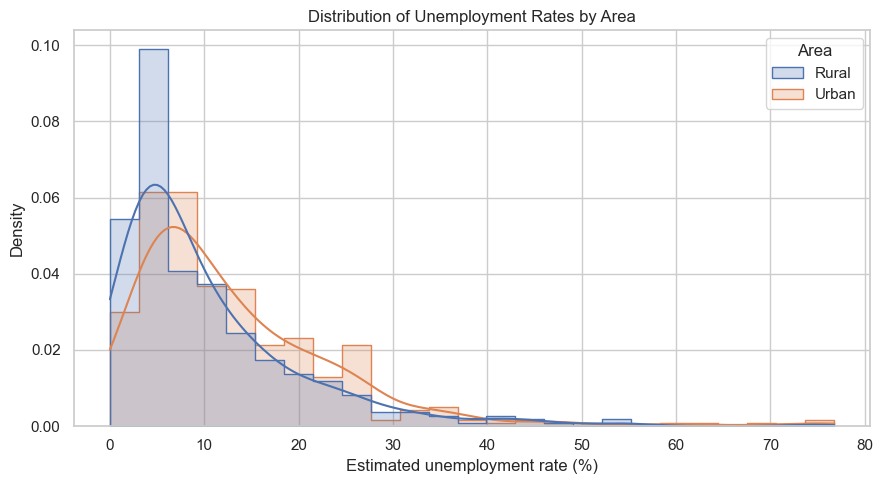

In [6]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=unemployment_area,
    x=rate_column,
    hue="Area",
    bins=25,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Distribution of Unemployment Rates by Area")
plt.xlabel("Estimated unemployment rate (%)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

### 6.2 Rural versus urban unemployment

,mean,median,std,count
Area,,,,
Rural,10.32,6.76,10.04,359
Urban,13.17,9.97,11.17,381


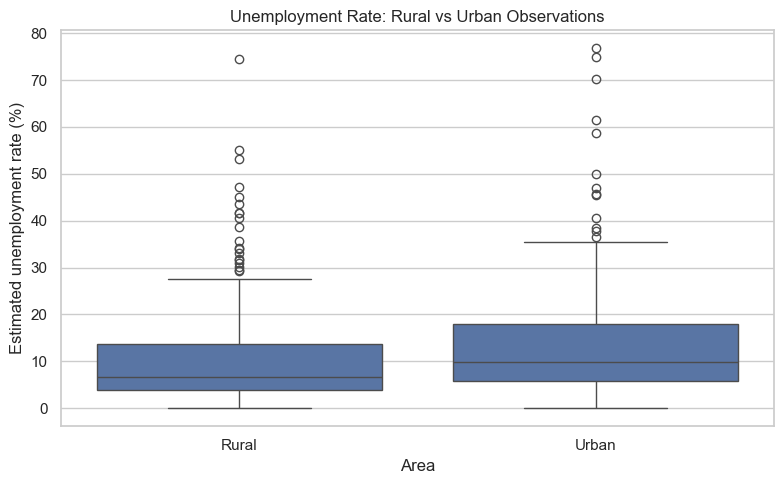

In [7]:
area_rate_summary = (
    unemployment_area.groupby("Area")[rate_column]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)
display(area_rate_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=unemployment_area, x="Area", y=rate_column)
plt.title("Unemployment Rate: Rural vs Urban Observations")
plt.xlabel("Area")
plt.ylabel("Estimated unemployment rate (%)")
plt.tight_layout()
plt.show()

### 6.3 Monthly unemployment trend

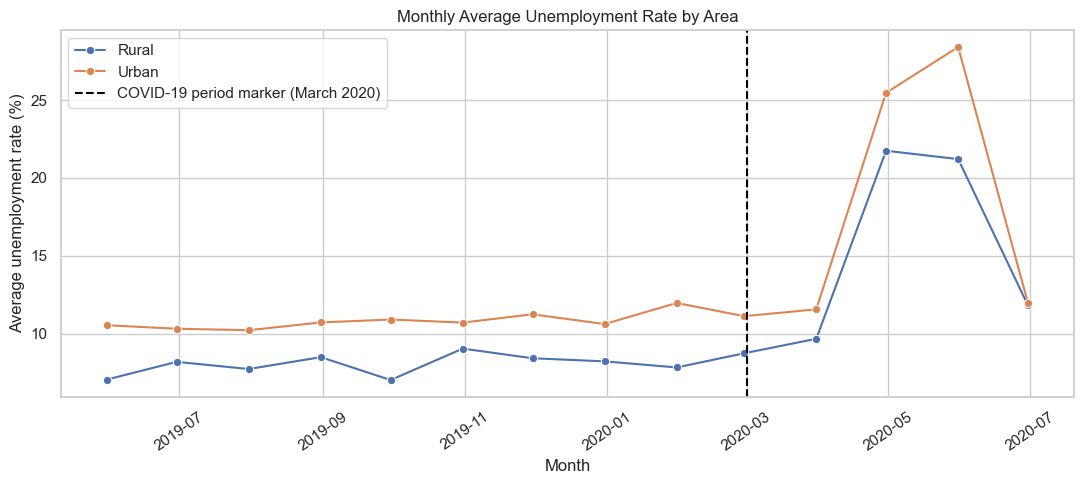

In [8]:
monthly_area_trend = (
    unemployment_area.groupby(["Date", "Area"], as_index=False)[rate_column]
    .mean()
    .sort_values("Date")
)

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=monthly_area_trend,
    x="Date",
    y=rate_column,
    hue="Area",
    marker="o"
)
plt.axvline(pd.Timestamp("2020-03-01"), color="black", linestyle="--",
            label="COVID-19 period marker (March 2020)")
plt.title("Monthly Average Unemployment Rate by Area")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

### 6.4 State-level unemployment rates

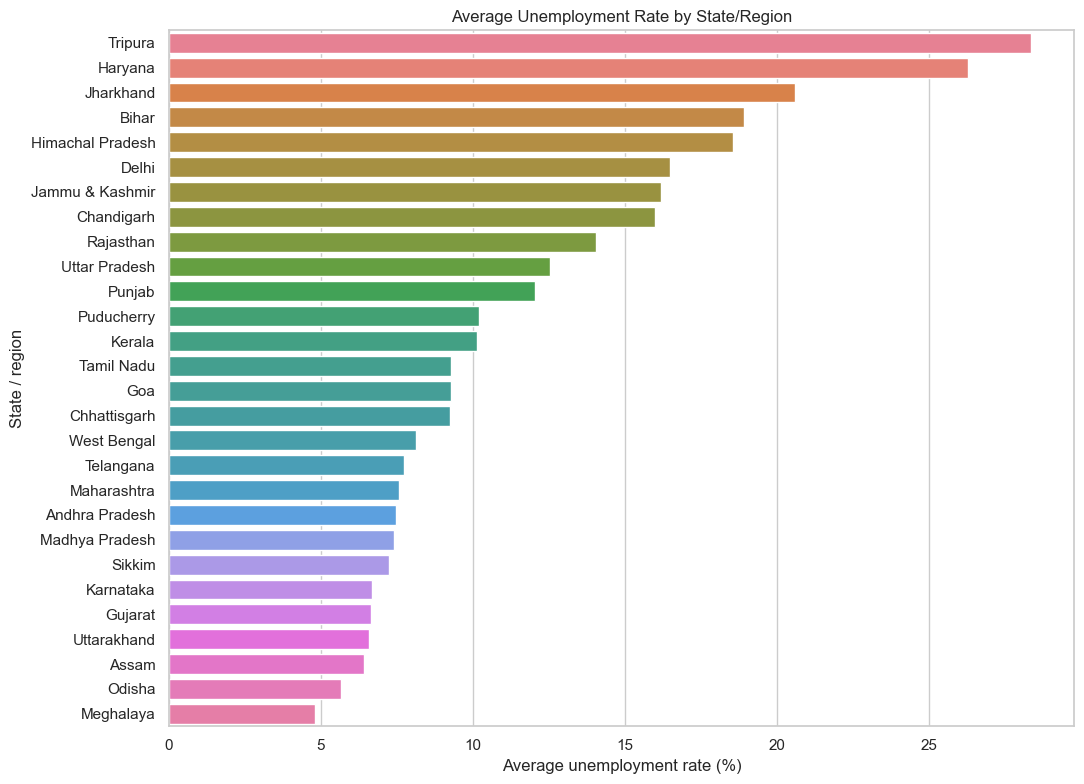

,Region,Average unemployment rate (%)
0,Tripura,28.35
1,Haryana,26.28
2,Jharkhand,20.58
3,Bihar,18.92
4,Himachal Pradesh,18.54
5,Delhi,16.50
6,Jammu & Kashmir,16.19
7,Chandigarh,15.99
8,Rajasthan,14.06
9,Uttar Pradesh,12.55


In [9]:
state_rate_summary = (
    unemployment_area.groupby("Region")[rate_column]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="Average unemployment rate (%)")
)

plt.figure(figsize=(11, 8))
sns.barplot(
    data=state_rate_summary,
    y="Region",
    x="Average unemployment rate (%)",
    hue="Region",
    dodge=False,
    legend=False
)
plt.title("Average Unemployment Rate by State/Region")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("State / region")
plt.tight_layout()
plt.show()

display(state_rate_summary.round(2))

### 6.5 Broad regional comparison

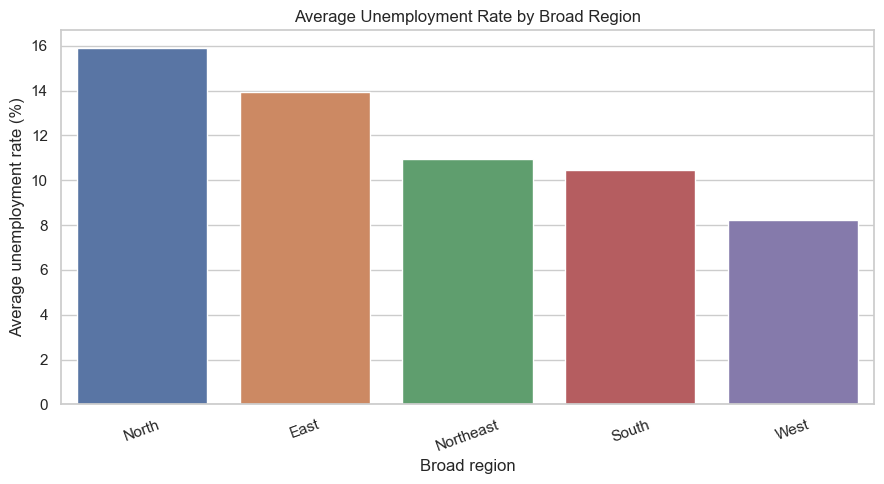

,Region.1,Average unemployment rate (%)
0,North,15.89
1,East,13.92
2,Northeast,10.95
3,South,10.45
4,West,8.24


In [10]:
broad_region_summary = (
    unemployment_region.groupby("Region.1")[rate_column]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="Average unemployment rate (%)")
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=broad_region_summary,
    x="Region.1",
    y="Average unemployment rate (%)",
    hue="Region.1",
    dodge=False,
    legend=False
)
plt.title("Average Unemployment Rate by Broad Region")
plt.xlabel("Broad region")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(broad_region_summary.round(2))

## 7. COVID-19 Impact Analysis

March 2020 is used as a descriptive marker for the start of the COVID-19 period in this analysis. The notebook compares the available pre-marker observations with observations from March 2020 onward. Because the first dataset ends in June 2020 and the second starts in January 2020, the comparison windows differ; results are interpreted within each dataset rather than merged as if they were identical samples.

In [11]:
COVID_START = pd.Timestamp("2020-03-01")

def compare_periods(dataframe, dataset_label):
    before = dataframe.loc[dataframe["Date"] < COVID_START, rate_column]
    during = dataframe.loc[dataframe["Date"] >= COVID_START, rate_column]
    summary = pd.DataFrame({
        "Period": ["Before March 2020", "March 2020 onward"],
        "Observations": [before.count(), during.count()],
        "Average unemployment rate (%)": [before.mean(), during.mean()],
        "Median unemployment rate (%)": [before.median(), during.median()],
    })
    print(dataset_label)
    display(summary.round(2))
    if before.notna().any() and during.notna().any():
        difference = during.mean() - before.mean()
        print(f"Difference in average rate (later minus earlier): {difference:.2f} percentage points")
    return summary

covid_area_comparison = compare_periods(unemployment_area, "Dataset 1 — state and area observations")
covid_region_comparison = compare_periods(unemployment_region, "Dataset 2 — regional observations")

Dataset 1 — state and area observations


,Period,Observations,Average unemployment rate (%),Median unemployment rate (%)
0,Before March 2020,536,9.51,7.12
1,March 2020 onward,204,17.77,14.52


Difference in average rate (later minus earlier): 8.26 percentage points
Dataset 2 — regional observations


,Period,Observations,Average unemployment rate (%),Median unemployment rate (%)
0,Before March 2020,52,9.23,6.66
1,March 2020 onward,215,12.96,10.11


Difference in average rate (later minus earlier): 3.73 percentage points


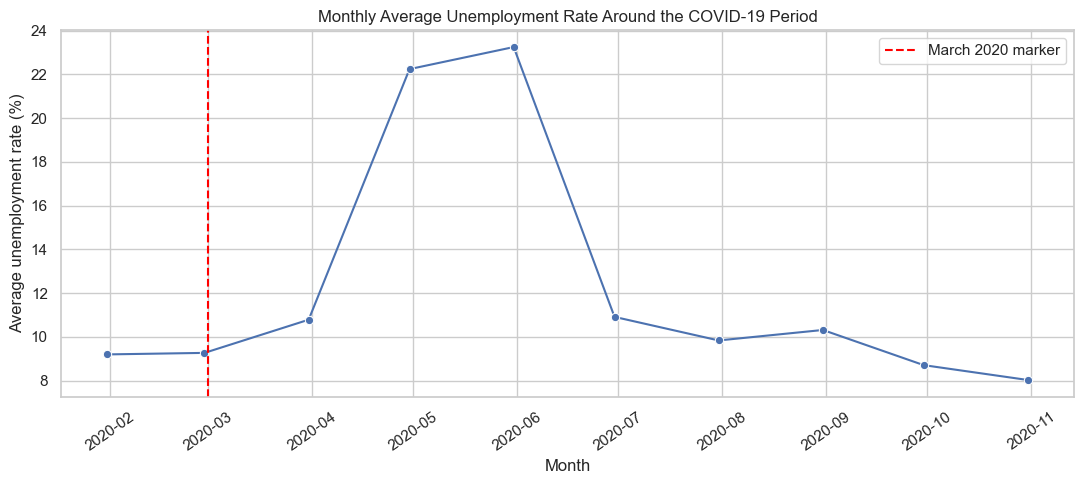

In [12]:
covid_monthly = (
    unemployment_region.groupby("Date", as_index=False)[rate_column]
    .mean()
    .sort_values("Date")
)

plt.figure(figsize=(11, 5))
sns.lineplot(data=covid_monthly, x="Date", y=rate_column, marker="o")
plt.axvline(COVID_START, color="red", linestyle="--", label="March 2020 marker")
plt.title("Monthly Average Unemployment Rate Around the COVID-19 Period")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Seasonal and Time-Based Patterns

The supplied observations cover roughly 14 months in the first file and 10 months in the second. This is not enough to verify a repeating annual seasonal cycle. The next chart therefore shows monthly averages by calendar month as an exploratory view only; differences may reflect the COVID-19 shock, state composition, or other time-specific factors rather than recurring seasonality.

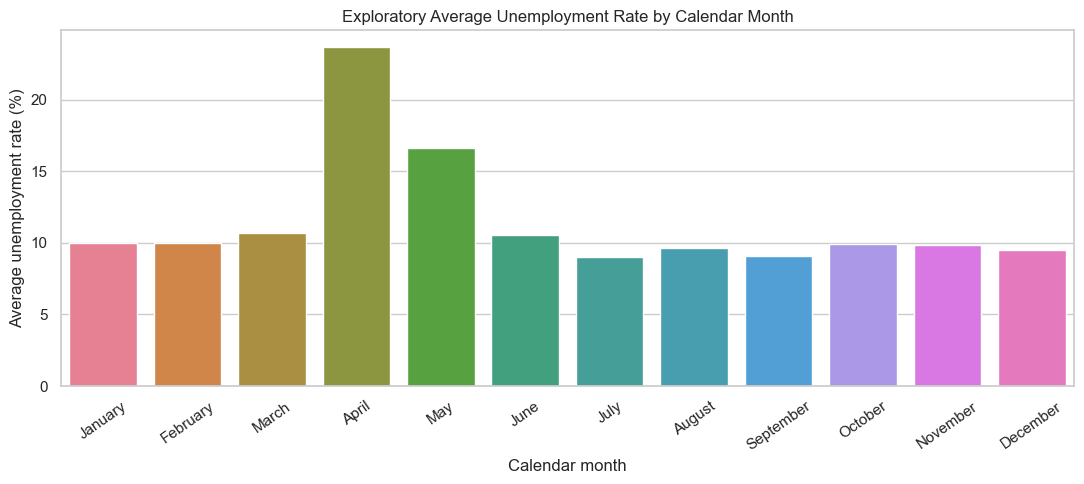

,Calendar month,Estimated Unemployment Rate (%)
0,January,9.95
1,February,9.96
2,March,10.70
3,April,23.64
4,May,16.65
5,June,10.55
6,July,9.03
7,August,9.64
8,September,9.05
9,October,9.90


In [13]:
seasonal_view = unemployment_area.copy()
seasonal_view["Calendar month"] = seasonal_view["Date"].dt.month_name()

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
calendar_month_summary = (
    seasonal_view.groupby("Calendar month")[rate_column]
    .mean()
    .reindex(month_order)
    .dropna()
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.barplot(data=calendar_month_summary, x="Calendar month", y=rate_column,
             hue="Calendar month", dodge=False, legend=False)
plt.title("Exploratory Average Unemployment Rate by Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

display(calendar_month_summary.round(2))

## 9. Key Findings and Policy-Relevant Insights

In [14]:
highest_state = state_rate_summary.iloc[0]
lowest_state = state_rate_summary.iloc[-1]
highest_broad_region = broad_region_summary.iloc[0]
lowest_broad_region = broad_region_summary.iloc[-1]
area_means = unemployment_area.groupby("Area")[rate_column].mean().sort_values(ascending=False)

print(f"Highest average state/region in dataset 1: {highest_state['Region']} "
      f"({highest_state['Average unemployment rate (%)']:.2f}%).")
print(f"Lowest average state/region in dataset 1: {lowest_state['Region']} "
      f"({lowest_state['Average unemployment rate (%)']:.2f}%).")
print(f"Highest average broad region in dataset 2: {highest_broad_region['Region.1']} "
      f"({highest_broad_region['Average unemployment rate (%)']:.2f}%).")
print(f"Lowest average broad region in dataset 2: {lowest_broad_region['Region.1']} "
      f"({lowest_broad_region['Average unemployment rate (%)']:.2f}%).")
print("\nAverage unemployment rate by area:")
display(area_means.to_frame("Average unemployment rate (%)").round(2))

print("\nPolicy interpretation:")
print("- State and area averages can help identify where additional employment support may be needed.")
print("- Changes after March 2020 highlight a period of labour-market disruption in the supplied observations.")
print("- Labour participation and employment estimates should be considered alongside unemployment rates.")
print("- These descriptive results do not establish causation and should be combined with broader economic evidence before policy decisions.")

Highest average state/region in dataset 1: Tripura (28.35%).
Lowest average state/region in dataset 1: Meghalaya (4.80%).
Highest average broad region in dataset 2: North (15.89%).
Lowest average broad region in dataset 2: West (8.24%).

Average unemployment rate by area:


,Average unemployment rate (%)
Area,
Urban,13.17
Rural,10.32



Policy interpretation:
- State and area averages can help identify where additional employment support may be needed.
- Changes after March 2020 highlight a period of labour-market disruption in the supplied observations.
- Labour participation and employment estimates should be considered alongside unemployment rates.
- These descriptive results do not establish causation and should be combined with broader economic evidence before policy decisions.


## 10. Conclusion

This analysis cleaned and explored two supplied unemployment datasets for India. It examined unemployment-rate distributions, rural/urban differences, state and broad-region patterns, monthly trends, and changes around the March 2020 COVID-19 marker.

The project reports descriptive statistics and visual evidence rather than claiming that the pandemic alone caused every observed change. The short observation window limits the strength of any seasonal conclusion. More years of monthly data, additional labour-market indicators, and external economic context would improve future analysis.

### Possible improvements
- Add multiple years of data to test recurring seasonal patterns.
- Include state-level population and industry indicators for deeper comparisons.
- Use statistical time-series methods to assess structural changes.
- Compare findings with official labour-market releases and other economic indicators.